# Asignación de deliberación: estado del arte

**Nivel:** 3  
**Requisitos previos:** Asignación de deliberación nivel 1  
**Tiempo de lectura:** 25 minutos

**Pregunta:** ¿La referencia XGBoost medida supera el resultado de esta muestra de delegación a nivel de caso?


## Objetivos

Para el nivel 3 de asignación de deliberación en C13, Separa la decisión rápida de una llamada opcional al planificador. Para el nivel 3 de asignación de deliberación en C13, Delegar solo sirve si el cambio en el resultado verificado independientemente compensa la demora, las propuestas inválidas y el trabajo no utilizado bajo el mismo estado observado de candidatos.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 3 de asignación de deliberación en C13, El notebook lee artefactos comprometidos del producto. Para el nivel 3 de asignación de deliberación en C13, Propietario: Para el nivel 3 de asignación de deliberación en C13, Neuraxis. Para el nivel 3 de asignación de deliberación en C13, Repositorio: Para el nivel 3 de asignación de deliberación en C13, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 3 de asignación de deliberación en C13, Apache-2.0. Para el nivel 3 de asignación de deliberación en C13, El JSON es un artefacto experimental propio y congelado; Para el nivel 3 de asignación de deliberación en C13, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 3 de asignación de deliberación en C13, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 3 de asignación de deliberación en C13, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 3 de asignación de deliberación en C13, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 3 de asignación de deliberación en C13, El manifiesto de publicación verifica los hashes. Para el nivel 3 de asignación de deliberación en C13, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 3 de asignación de deliberación en C13, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/semantic-routing-study/analysis.json`
- `data/derived/episodes/M11-C13-nominal-40000.json`
- `data/derived/episodes/M12-C13-nominal-40000.json`
- `data/derived/episodes/M09-C13-nominal-40000.json`
- `data/derived/episodes/M10-C13-nominal-40000.json`


## Método

Para el nivel 3 de asignación de deliberación en C13, La respuesta de un planificador es una propuesta con costo medido, no una mejora automática. Para el nivel 3 de asignación de deliberación en C13, El controlador rápido observa candidatos acotados; Para el nivel 3 de asignación de deliberación en C13, el planificador recibe solo la solicitud permitida por su interfaz y puede devolver una respuesta tardía, inválida o no utilizada. Para el nivel 3 de asignación de deliberación en C13, La comparación pertinente se empareja por características e historia causal, y luego cobra el tiempo transcurrido del planificador. Para el nivel 3 de asignación de deliberación en C13, La puerta ajustada de Neuraxis tuvo solo siete etiquetas positivas entre 228 estados y seleccionó umbral 1,01, por lo que nunca superó el umbral de delegación. Para el nivel 3 de asignación de deliberación en C13, Es un resultado negativo de este ajuste y selección, no una prueba de que todo sistema rápido/lento falle. Para el nivel 3 de asignación de deliberación en C13, Ollama local es opcional y no debe confundirse con las trazas congeladas del planificador. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, Una puerta de delegación compara el valor esperado de la respuesta lenta con el resultado verificado de la política rápida, incluida la latencia, propuestas inválidas y razonamiento sin uso. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, Las trazas C13 muestran cuándo el controlador experimental pidió deliberación, pero una reproducción no demuestra que un modelo activo responda bien con contexto modificado. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, Un ensayo justo empareja ejecuciones rápidas y delegadas sobre la misma observación, herramientas y contrato, y registra calidad de decisión y coste temporal por separado. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, Los ejemplos positivos deben incluir situaciones donde deliberar cambia una decisión relevante. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, sin ellos, una puerta que nunca delega puede parecer exitosa sin aprender asignación. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, Un modelo de lenguaje es un componente externo estocástico. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, registra identidad, prompt, parámetros de decodificación, límites de tiempo y manejo de salidas inválidas. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, En este nivel, registra si la puerta invoca al planificador, si su propuesta es admisible y si el resultado verificado cambia después de pagar la demora. Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, Una extensión útil incorpora observaciones ambiguas con valor positivo de delegación y controles negativos donde la política rápida ya es suficiente.


### asignación de deliberación · nivel 3 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M11", "M12", "M09", "M10"]
trace_methods = ["M11", "M12", "M09", "M10", "M04"]
sample_case = "C13"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 5


### asignación de deliberación · nivel 3 — Ejecuta las políticas publicadas y compara la corrida


### asignación de deliberación · nivel 3 — Compara la secuencia completa y no solo la primera acción


### asignación de deliberación · nivel 3 — Recalcula resultados por variante desde todas las trazas del caso


In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M09 boundary successes= 1 episodes= 10 rate= 0.1
M09 delayed_observation successes= 2 episodes= 10 rate= 0.2
M09 duplicate_event successes= 5 episodes= 10 rate= 0.5
M09 nominal successes= 4 episodes= 10 rate= 0.4
M09 stale_conflict successes= 2 episodes= 10 rate= 0.2
M09 unavailable_dependency successes= 3 episodes= 10 rate= 0.3
M10 boundary successes= 10 episodes= 10 rate= 1.0
M10 delayed_observation successes= 10 episodes= 10 rate= 1.0
M10 duplicate_event successes= 10 episodes= 10 rate= 1.0
M10 nominal successes= 10 episodes= 10 rate= 1.0
M10 stale_conflict successes= 10 episodes= 10 rate= 1.0
M10 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M11 boundary successes= 10 episodes= 10 rate= 1.0
M11 delayed_observation successes= 10 episodes= 10 rate= 1.0
M11 duplicate_event successes= 10 episodes= 10 rate= 1.0
M11 nominal successes= 10 episodes= 10 rate= 1.0
M11 stale_conflict successes= 10 episodes= 10 rate= 1.0
M11 unavailable_dependency successes= 10 episodes= 10 rate=

### asignación de deliberación · nivel 3 — Visualiza el estrés por variante sin mezclar familias


In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### Audita el estudio de enrutamiento por separado


In [5]:
# Este experimento offline no se combina con el benchmark central.
routing = json.loads((ROOT / "data/derived/semantic-routing-study/analysis.json").read_text(encoding="utf-8"))
print(
    "threshold=",
    routing["selected_threshold"],
    "| fit positives=",
    routing["fit_positives"],
    "| calibration positives=",
    routing["calibration_positives"],
)
for arm, result in routing["test"].items():
    print(arm, result)


threshold= 0.44629505030857797 | fit positives= 19 | calibration positives= 8
always_fast_M04 {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
always_planner_M09 {'episodes': 32, 'invalid_policy_outputs': 8, 'mean_wall_ms': 20052.693393749905, 'planner_episodes': 32, 'verified_successes': 10}
hash_half {'episodes': 32, 'invalid_policy_outputs': 4, 'mean_wall_ms': 11568.068874998971, 'planner_episodes': 19, 'verified_successes': 7}
learned_gate {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
post_hoc_oracle_upper_bound {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 4085.057468750165, 'planner_episodes': 10, 'verified_successes': 10}


### asignación de deliberación · L3 — Construir la primera política ejecutable

En el nivel 3, construye M11 para asignación de deliberación con la fábrica pública y conserva su contrato de observación antes de muestrear C13.


In [6]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M11"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M11


### asignación de deliberación · L3 — Ejecutar el método principal en el caso indicado

En el nivel 3 de asignación de deliberación, el evaluador ejecuta M11 en C13 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [7]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### asignación de deliberación · L3 — Construir una política de comparación independiente

Para el nivel 3 de asignación de deliberación, crea M12 como objeto nuevo para impedir que el estado recurrente de M11 contamine la comparación.


In [8]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M12"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M12


### asignación de deliberación · L3 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M12 en el mismo C13, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [9]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### asignación de deliberación · L3 — Agregar los dos episodios ejecutados

En el nivel 3, el agregador resume dos episodios ejecutados de asignación de deliberación, and las afirmaciones entre familias aún requieren el benchmark completo.


In [10]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### asignación de deliberación · L3 — Resultados de políticas nuevas

Para el nivel 3 de asignación de deliberación en C13, El gráfico siguiente se calcula con los resultados de episodios de asignación de deliberación recién ejecutados en C13, no se copia de un artefacto congelado.


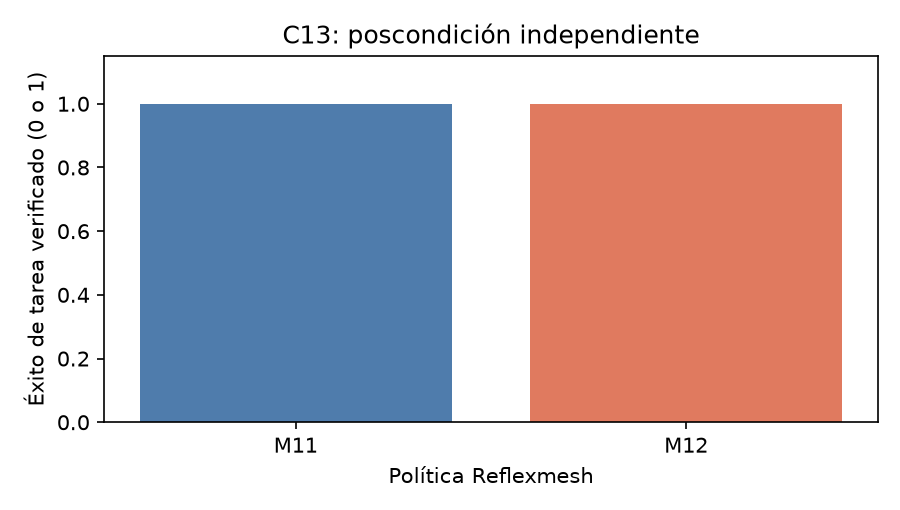

In [11]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 3 de asignación de deliberación en C13, Para asignación de deliberación, estas barras muestran resultados nuevos de poscondición de M11 y M12 en C13; Para el nivel 3 de asignación de deliberación en C13, éxito vale 1 y falla 0. Para el nivel 3 de asignación de deliberación en C13, Lee el caso y la semilla antes de compararlas. Para el nivel 3 de asignación de deliberación en C13, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


## Estado del arte

En el nivel 3, para asignación de deliberación en C13, La investigación de valor de cómputo y aprendizaje con aplazamiento formaliza si otra computación justifica su costo. En el nivel 3, para asignación de deliberación en C13, Las cantidades pertinentes incluyen utilidad incremental esperada, demora del planificador, respuesta inválida y llegada antes de que cambie el estado. En el nivel 3, para asignación de deliberación en C13, Las puertas ajustadas de Neuraxis nunca delegaron con el umbral seleccionado y este resultado negativo se conserva. En el nivel 3, para asignación de deliberación en C13, M04 proporciona una comparación aprendida ejecutada en la misma tarea C13. En el nivel 3, para asignación de deliberación en C13, En el nivel 3, para asignación de deliberación en C13, no es un planificador. En el nivel 3, para asignación de deliberación en C13, Una llamada Ollama configurada sería otra medición y no se simula a partir de trazas congeladas.


### asignación de deliberación · L3 — Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para asignación de deliberación ejecuta M04 en C13 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.


In [12]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("State-of-the-art comparator runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


State-of-the-art comparator runs: 1
XGBoost task success: 1


### asignación de deliberación · L3 | Tiempo registrado del controlador

En el nivel 3, la figura de tiempos de asignación de deliberación usa registros congelados y verificados por hash para M11 y M04 en C13, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para asignación de deliberación describe el entorno registrado bajo su caso, variante y semilla declarados.

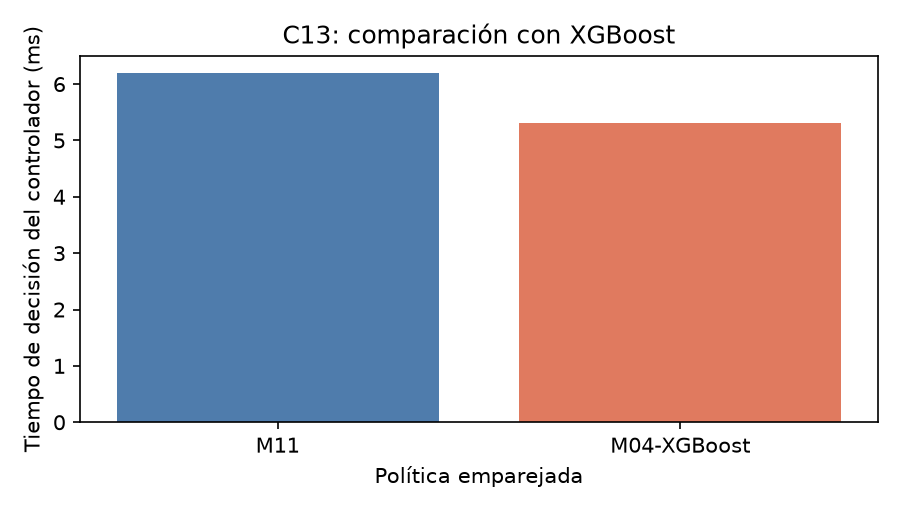

In [13]:
# Compare hash-verified canonical controller times under the same case, variant and seed.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política emparejada")
ax.set_title(f"{sample_case}: comparación con XGBoost")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para asignación de deliberación lee registros canónicos de M11/M04 en C13, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En esta lección de asignación de deliberación, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de nivel 3 para asignación de deliberación contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C13; esas 3 corridas emparejadas no establecen superioridad poblacional para asignación de deliberación.

Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, El ajuste de la puerta usó 228 estados con siete etiquetas positivas y seleccionó el umbral 1,01, por lo que nunca delegó a través de esa puerta. Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, El otro disparador de M12 es independiente. Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Informa llamadas al planificador, latencia y éxito verificado; Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, configurar un LLM no demuestra que deliberar sea útil.

Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Este paso de autoría no compromete salidas generadas; Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, Para el nivel 3 de asignación de deliberación en C13, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 3 de asignación de deliberación en C13, En el nivel 3, asignación de deliberación usa C13 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 3 de asignación de deliberación en C13, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [DPT](https://aclanthology.org/2025.acl-long.206/)
- [VOC](https://arxiv.org/abs/1711.06892)
- [DEFER](https://proceedings.mlr.press/v119/mozannar20b.html)
